In [170]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from astropy.time import Time
import astropy.units as u
from astropy.coordinates import Angle
from astropy.coordinates import SkyCoord

In [171]:
# Convert to degrees
def convert_coords(ra_coords, dec_coords):
    new_vals = SkyCoord(ra_coords, dec_coords, unit = (u.hourangle, u.deg))

    return new_vals


In [172]:
tns_file = pd.read_csv("tns_search.csv")
matched_file = pd.read_csv("ztf_tns_matches_20arcsec.csv")

In [173]:
coordinates = convert_coords(tns_file['RA'].values, tns_file['DEC'].values)
ra_deg = coordinates.ra
dec_deg = coordinates.dec

# Converting everything to radians (mollweide needs radians)
ra_rad = ra_deg.wrap_at('180d').radian # mollweide needs between -180 and 180 deg
dec_rad = dec_deg.radian

In [174]:
match_coordinates = convert_coords(matched_file['RA_x'].values, matched_file['Dec'].values)
match_ra_deg = match_coordinates.ra
match_dec_deg = match_coordinates.dec

match_ra_rad = match_ra_deg.wrap_at('180d').radian 
match_dec_rad = match_dec_deg.radian

Text(0.5, 1.0, 'TNS vs ZTF matched to TNS')

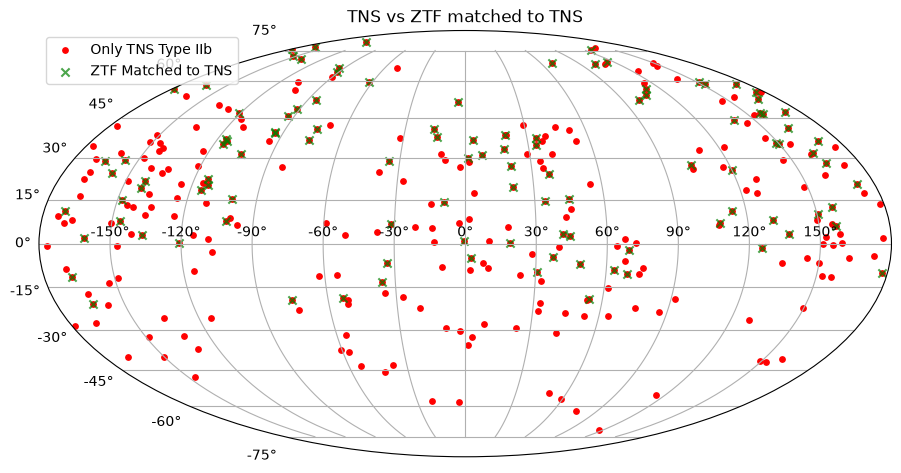

In [175]:
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="mollweide")

ax.scatter(ra_rad,
           dec_rad,
           s=15,
           color = 'red',
           alpha=1,
           label = "Only TNS Type IIb")

ax.scatter(match_ra_rad,
           match_dec_rad,
           s=35,
           alpha = 0.7,
           color='green',
           marker = 'x',
           label="ZTF Matched to TNS")

ax.grid(True)
ax.legend()
ax.set_title("TNS vs ZTF matched to TNS")

Text(0.5, 1.0, 'ZTF Matched to TNS Projection')

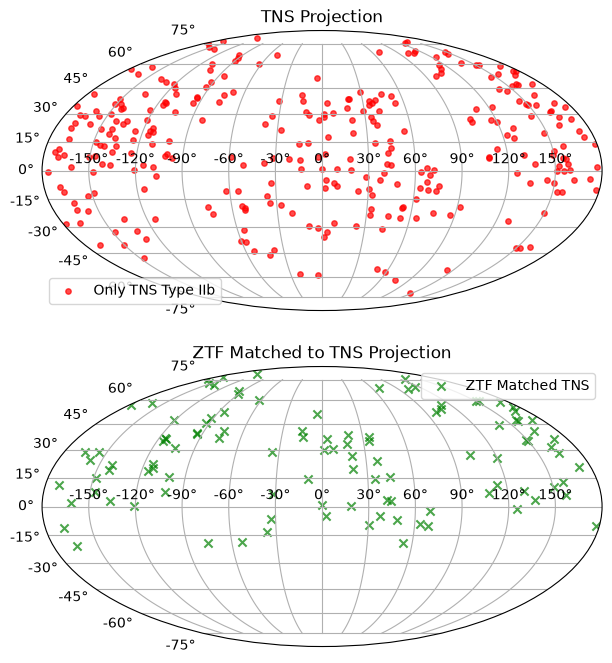

In [176]:
# https://milkyway-plot.readthedocs.io/en/latest/matplotlib_multi.html

fig = plt.figure(figsize = (11,8))

ax1 = fig.add_subplot(211, projection = 'mollweide')
ax2 = fig.add_subplot(212, projection = 'mollweide')

ax1.scatter(ra_rad,
           dec_rad,
           s=15,
           color = 'red',
           alpha=0.7,
           label = "Only TNS Type IIb")

ax2.scatter(match_ra_rad,
           match_dec_rad,
           s=35,
           alpha = 0.7,
           color='green',
           marker = 'x',
           label="ZTF Matched TNS")

ax1.grid(True)
ax2.grid(True)


ax1.legend()
ax2.legend()

ax1.set_title("TNS Projection")
ax2.set_title("ZTF Matched to TNS Projection")

In [177]:
# Mollweide ZTF Coverage
ztf_file = pd.read_csv("ztf_new.csv")


In [178]:
# Separate SNII w/ SNIIb

# Ignores all Supernovae with a probability of less than 0.5
ignored = ztf_file['probability'] < 0.8 # less than 0.5
ignored_sn = ztf_file.loc[ignored, 'oid'].tolist() # find where ignored == True and keep those in a list

# Probability > 0.5
good = ztf_file[ztf_file['probability'] >= 0.8]

# Filter based on SNII
good_snii = good[good['class'] == "SNII"]

snii_ztf_ra = Angle(good_snii['meanra'].values * u.deg)
snii_ztf_ra = snii_ztf_ra.wrap_at('180d').radian

snii_ztf_dec = Angle((good_snii['meandec'].values * u.deg))
snii_ztf_dec = snii_ztf_dec.radian

# Filter based on SNIIb
good_sniib = good[good['class'] == "SNIIb"]

sniib_ztf_ra = Angle(good_sniib['meanra'].values * u.deg)
sniib_ztf_ra = sniib_ztf_ra.wrap_at('180d').radian

sniib_ztf_dec = Angle((good_sniib['meandec'].values * u.deg))
sniib_ztf_dec = sniib_ztf_dec.radian


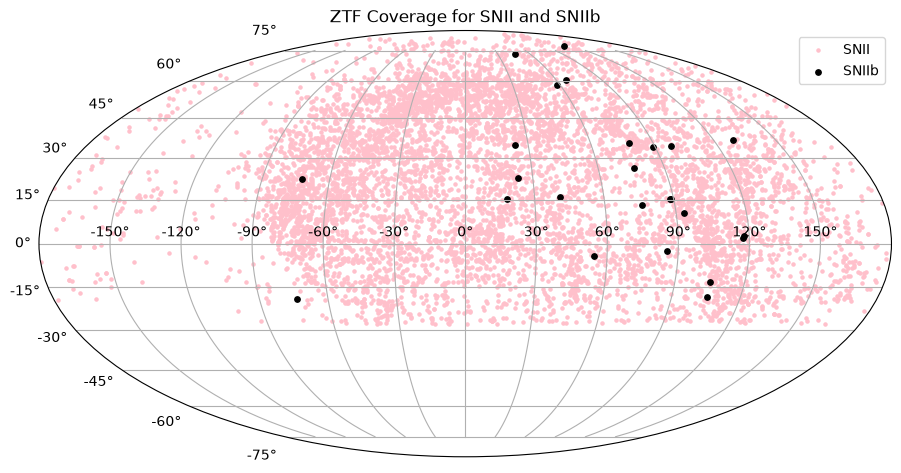

In [179]:
fig = plt.figure(figsize = (11, 8))
ax = fig.add_subplot(111, projection = "mollweide")

ax.scatter(snii_ztf_ra,
           snii_ztf_dec,
           color = 'pink',
           s = 5,
           label = 'SNII')

ax.scatter(sniib_ztf_ra,
           sniib_ztf_dec,
           color = 'black',
           s = 15,
           label = 'SNIIb')

ax.legend()
ax.set_title("ZTF Coverage for SNII and SNIIb")
ax.grid(True)

In [182]:
# Unmatched TNS 
unmatched_file = pd.read_csv("ztf_tns_unmatched.csv")

unmatch_coordinates = convert_coords(unmatched_file['RA'].values, unmatched_file['DEC'].values)
unmatch_ra_deg = unmatch_coordinates.ra
unmatch_dec_deg = unmatch_coordinates.dec

unmatch_ra_rad = unmatch_ra_deg.wrap_at('180d').radian 
unmatch_dec_rad = unmatch_dec_deg.radian

Text(0.5, 1.0, 'TNS vs ZTF unmatched to TNS')

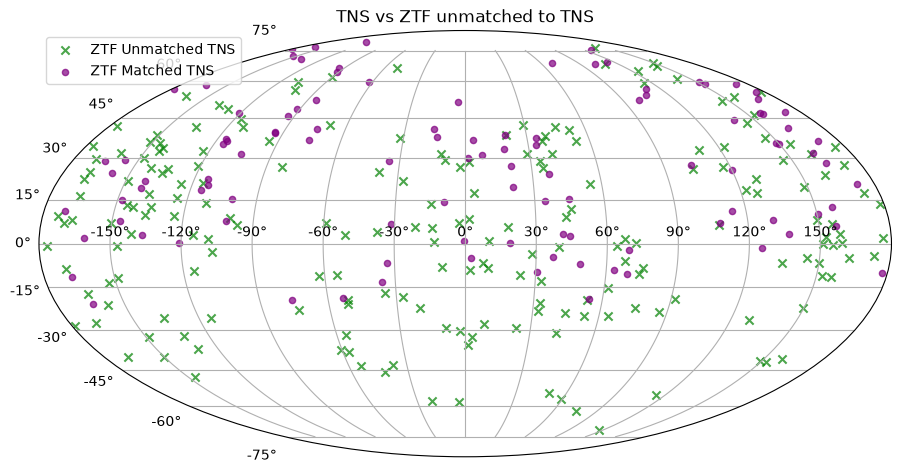

In [183]:
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="mollweide")

ax.scatter(unmatch_ra_rad,
           unmatch_dec_rad,
           s=35,
           alpha = 0.7,
           color='green',
           marker = 'x',
           label="ZTF Unmatched TNS")

ax.scatter(match_ra_rad,
           match_dec_rad,
           s=20,
           alpha = 0.7,
           color='purple',
           marker = 'o',
           label="ZTF Matched TNS")

ax.grid(True)
ax.legend()
ax.set_title("TNS vs ZTF unmatched to TNS")